# chemca test notebook

For N, 2026-10-24. Pre-merge checks for branch `chemca` (Docs/plan-chemca.md).
Brief PASS/FAIL cells, then figures: colorize frames of fw2 and gs3, mass and energy
budget traces, mean k over time, the gs3 (S3 rates) wave report at N = 128 and 256, and
the isologous-diversification readout with genes frozen.

Headless: no SDL calls. Run with `EVOCA_NO_DISPLAY=1 jupyter nbconvert --execute`.

In [1]:
import os, sys, time
import numpy as np
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
%matplotlib inline

ROOT = os.getcwd()
while not os.path.exists(os.path.join(ROOT, 'C', 'chemca.h')):
    ROOT = os.path.dirname(ROOT)
sys.path.insert(0, os.path.join(ROOT, 'python'))
sys.path.insert(0, os.path.join(ROOT, 'tests'))
import evoca_build
evoca_build.build(ROOT)
import chemca_py as cp
import evoca_explore as ee, evoca_nb, evoca_py, evoca_waves
from chemca_helpers import isolated, cell
RESULTS = {}

def check(name, ok, detail=''):
    RESULTS[name] = bool(ok)
    print(('PASS' if ok else 'FAIL'), name, detail)

## 1. PASS/FAIL checks

In [2]:
# Conversion: single cell, catalyzed m = 2, against a (1 - exp(-k c^2)).
import math
sim = isolated(genes=[cp.gene('F', 'A', 'A', 2, 40)], stores=dict(F=0.8, A=0.3))
sim.step()
k = sim.k_of(40); conv = 0.8 * (1 - math.exp(-k * 0.3 ** 2))
got = 0.8 - cell(sim.get_store('F'))
check('conversion m=2 matches exponential integrator', abs(got - conv) < 1e-6 * 0.8, f'{got:.7f} vs {conv:.7f}')
sim.free()

# Mass and energy identities every step, both presets, closed mode, mutation on.
for pre in ('fw2', 'gs3'):
    r = cp.run_chemca(dict(model='chemca', preset=pre, mu_rgene=0.02, mu_ractive=0.02),
                      n_steps=1500, N=128, seed=1, kymo_steps=200)
    check(f'{pre}: mass identity (rel. err < 1e-6)', r['mass_err_max'] < 1e-6, f"max {r['mass_err_max']:.1e}")
    check(f'{pre}: energy identity (abs. err < 1e-9)', r['energy_err_max'] < 1e-9, f"max {r['energy_err_max']:.1e}")
    check(f'{pre}: population persists 1500 steps at N=128', not r['extinct'], f"final {r['alive_final']:.2f}")

PASS conversion m=2 matches exponential integrator 0.0704326 vs 0.0704326


PASS fw2: mass identity (rel. err < 1e-6) max 5.2e-07
PASS fw2: energy identity (abs. err < 1e-9) max 0.0e+00
PASS fw2: population persists 1500 steps at N=128 final 0.11


PASS gs3: mass identity (rel. err < 1e-6) max 1.3e-07
PASS gs3: energy identity (abs. err < 1e-9) max 0.0e+00
PASS gs3: population persists 1500 steps at N=128 final 0.15


In [3]:
# Recipe round trip and dispatch.
import tempfile
d = tempfile.mkdtemp()
s = cp.build_chemca(dict(model='chemca', preset='gs3', mu_rgene=0.05), N=32, seed=4)
path = s.export_recipe('nb_rt', runs_dir=d); s.step(200); h1 = s.state_hash(); s.free()
s2, _ = evoca_py.import_run(path); s2.step(200)
check('recipe round trip: identical state hash', s2.state_hash() == h1); s2.free()
e, _ = evoca_py.import_run(os.path.join(ROOT, 'Research/Chem/Runs/2026-10-23_chem_fw_spiralpoint.evoca'), N=32)
check('recipe without model loads as EvoCA', isinstance(e, evoca_py.EvoCA)); e.free()
b = ee.build_sim(dict(model='chemca', preset='fw2', light=0.02), N=16)
check('build_sim dispatches to ChemCA', isinstance(b, cp.ChemCA)); b.free()
m = evoca_nb.make_sim(16, model='chemca', preset='gs3')
check('make_sim dispatches to ChemCA', isinstance(m, cp.ChemCA)); m.free()

PASS recipe round trip: identical state hash 
PASS recipe without model loads as EvoCA 
PASS build_sim dispatches to ChemCA 
PASS make_sim dispatches to ChemCA 


In [4]:
# Mass gate: division exactly at doubling of body mass (body = A, u_A = 0).
sim = isolated(genes=[cp.gene('F', 'A', 'A', 2, 31)], stores=dict(F=0.3, A=0.2), E=dict(F=0.3),
               u_F=0.5, u_P=0.5, repro_gate='mass', mass_repro=0.4)
prev = 0.2
for t in range(200):
    sim.step()
    if sim.events_last()['births']:
        break
    prev = cell(sim.get_store('A'))
a_div = 2 * cell(sim.get_store('A'))
check('mass gate: divides on the first step with body >= 2 x birth mass', prev < 0.4 <= a_div,
      f'step {t+1}: before {prev:.3f}, at division {a_div:.3f}')
sim.free()

# composition_clusters on constructed populations.
def planted(blocks, N=32):
    s = cp.ChemCA(); s.init(N, preset='gs3'); s.state(alive='all', seed=0)
    rng = np.random.default_rng(0); band = np.arange(N) * len(blocks) // N
    for ci, c in enumerate('FAP'):
        v = np.array([b[ci] for b in blocks])[band][None, :].repeat(N, 0)
        s.set_store(c, v * (1 + 0.01 * rng.standard_normal((N, N))))
    return s
s = planted([(0.4, 0.1, 0.1)]); n1 = cp.composition_clusters(s)['n_clusters']; s.free()
s = planted([(0.4, 0.1, 0.1), (0.1, 0.3, 0.2)]); n2 = cp.composition_clusters(s)['n_clusters']; s.free()
check('composition_clusters: homogeneous -> 1, two planted -> 2', (n1, n2) == (1, 2), f'{n1}, {n2}')

PASS mass gate: divides on the first step with body >= 2 x birth mass step 46: before 0.394, at division 0.401


PASS composition_clusters: homogeneous -> 1, two planted -> 2 1, 2


## 2. Frames: fw2 and gs3 at N = 128 after 3000 steps (provisional presets)

fw2 alive 0.42 k_idx by type {'F->W': (6882, 29.0)}


gs3 alive 0.214 k_idx by type {'F->A [A^2]': (3507, 50.0), 'A->P': (3507, 27.0)}


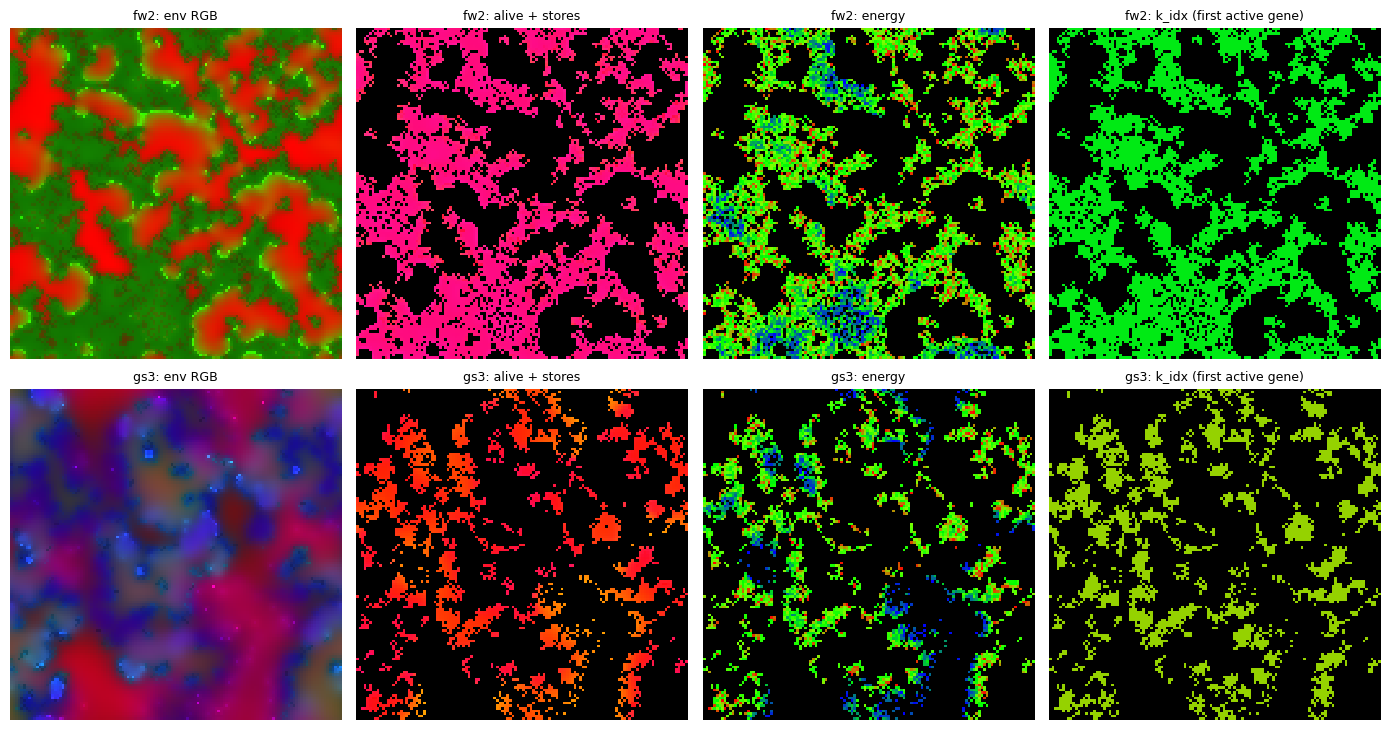

In [5]:
FR = {}
for pre in ('fw2', 'gs3'):
    s = cp.build_chemca(dict(model='chemca', preset=pre), N=128, seed=1)
    s.step(3000)
    FR[pre] = [s.rgb(m) for m in range(s.colormode_count())]
    print(pre, 'alive', round(s.population() / 128 ** 2, 3), 'k_idx by type', s.k_idx_by_type())
    s.free()
fig, axs = plt.subplots(2, 4, figsize=(14, 7.5))
for i, pre in enumerate(('fw2', 'gs3')):
    for m in range(4):
        axs[i, m].imshow(FR[pre][m], interpolation='nearest'); axs[i, m].axis('off')
        axs[i, m].set_title(f'{pre}: {cp.ChemCA.COLORMODE_NAMES[m]}', fontsize=9)
fig.tight_layout(); plt.show()

## 3. Budget traces and mean k over time (mutation on, mu = 0.02), N = 128

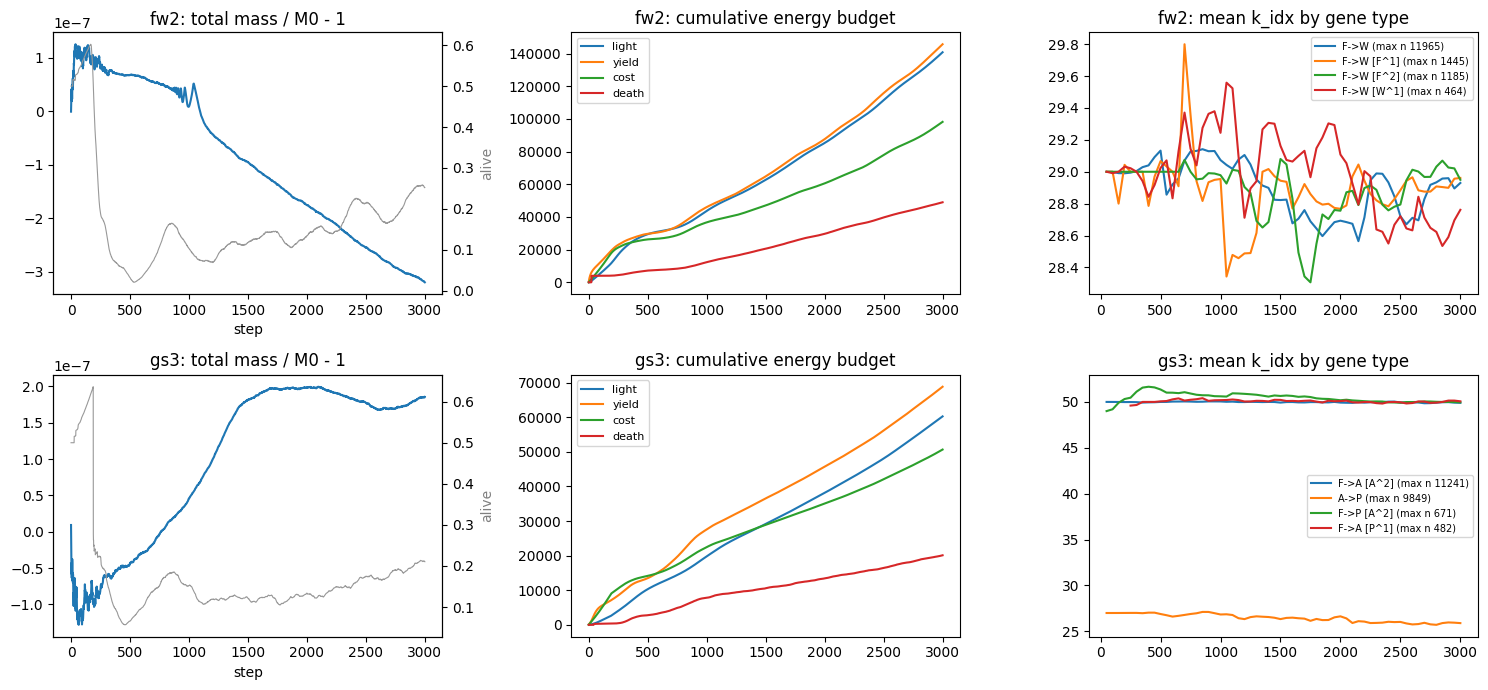

In [6]:
fig, axs = plt.subplots(2, 3, figsize=(15, 7))
for i, pre in enumerate(('fw2', 'gs3')):
    s = cp.build_chemca(dict(model='chemca', preset=pre, mu_rgene=0.02, mu_ractive=0.02), N=128, seed=2)
    M0 = s.mass()['total']; mass_err, alive, cum, kmean, ts = [], [], [], {}, []
    for t in range(1, 3001):
        s.step()
        mass_err.append(s.mass()['total'] / M0 - 1); alive.append(s.population() / 128 ** 2)
        cum.append(s.energy_budget(cum=True))
        if t % 50 == 0:
            ts.append(t)
            for name, (n, k) in s.k_idx_by_type().items():
                kmean.setdefault(name, []).append((t, n, k))
    s.free()
    axs[i, 0].plot(mass_err); axs[i, 0].set_title(f'{pre}: total mass / M0 - 1'); axs[i, 0].set_xlabel('step')
    for key in ('light', 'yield', 'cost', 'death'):
        axs[i, 1].plot([c[key] for c in cum], label=key)
    axs[i, 1].set_title(f'{pre}: cumulative energy budget'); axs[i, 1].legend(fontsize=8)
    for name, rows in sorted(kmean.items(), key=lambda kv: -max(r[1] for r in kv[1]))[:4]:
        rows = np.array(rows)
        axs[i, 2].plot(rows[:, 0], rows[:, 2], label=f'{name} (max n {int(rows[:, 1].max())})')
    axs[i, 2].set_title(f'{pre}: mean k_idx by gene type'); axs[i, 2].legend(fontsize=7)
    ax2 = axs[i, 0].twinx(); ax2.plot(alive, color='0.6', lw=0.8); ax2.set_ylabel('alive', color='0.5')
fig.tight_layout(); plt.show()

## 4. gs3 at the S3 rates: persistence, period, waves (N = 128, 256)

gs3 defaults are set S3 of the closed-loop Gray-Scott study (k1 = 6.0 -> k_idx 50, k = 5.79;
k2 = 0.1 -> k_idx 27, k = 0.108; light r = 0.005; diffusion 0.6/0.3/0.3), with reactions
running only inside agents. The study (pure chemistry) gives spiral period about 345 steps,
wavelength about 47.

Rows 3-4: the same k_idx with k_min = 0.01, i.e. both rates x10 (k1 = 58, k2 = 1.08;
a = k1/k2 unchanged at 54, light unchanged). During tuning this variant (which an earlier
draft of the preset used by accident) gave sharp traveling excitation fronts.

S3 128 {'alive_mean': 0.206, 'alive_std': 0.021, 'alive_min': 0.154, 'site_period_alive': (nan, 0.04), 'site_period_A': (nan, 0.09), 'global_period': (956.0, 0.36)}


S3 256 {'alive_mean': 0.181, 'alive_std': 0.019, 'alive_min': 0.142, 'site_period_alive': (nan, 0.03), 'site_period_A': (nan, 0.03), 'global_period': (nan, -0.27)}


S3 x10 128 {'alive_mean': 0.236, 'alive_std': 0.063, 'alive_min': 0.112, 'site_period_alive': (447.0, 0.27), 'site_period_A': (nan, 0.09), 'global_period': (499.0, 0.46)}


S3 x10 256 {'alive_mean': 0.234, 'alive_std': 0.035, 'alive_min': 0.168, 'site_period_alive': (447.0, 0.34), 'site_period_A': (nan, 0.12), 'global_period': (488.0, 0.39)}


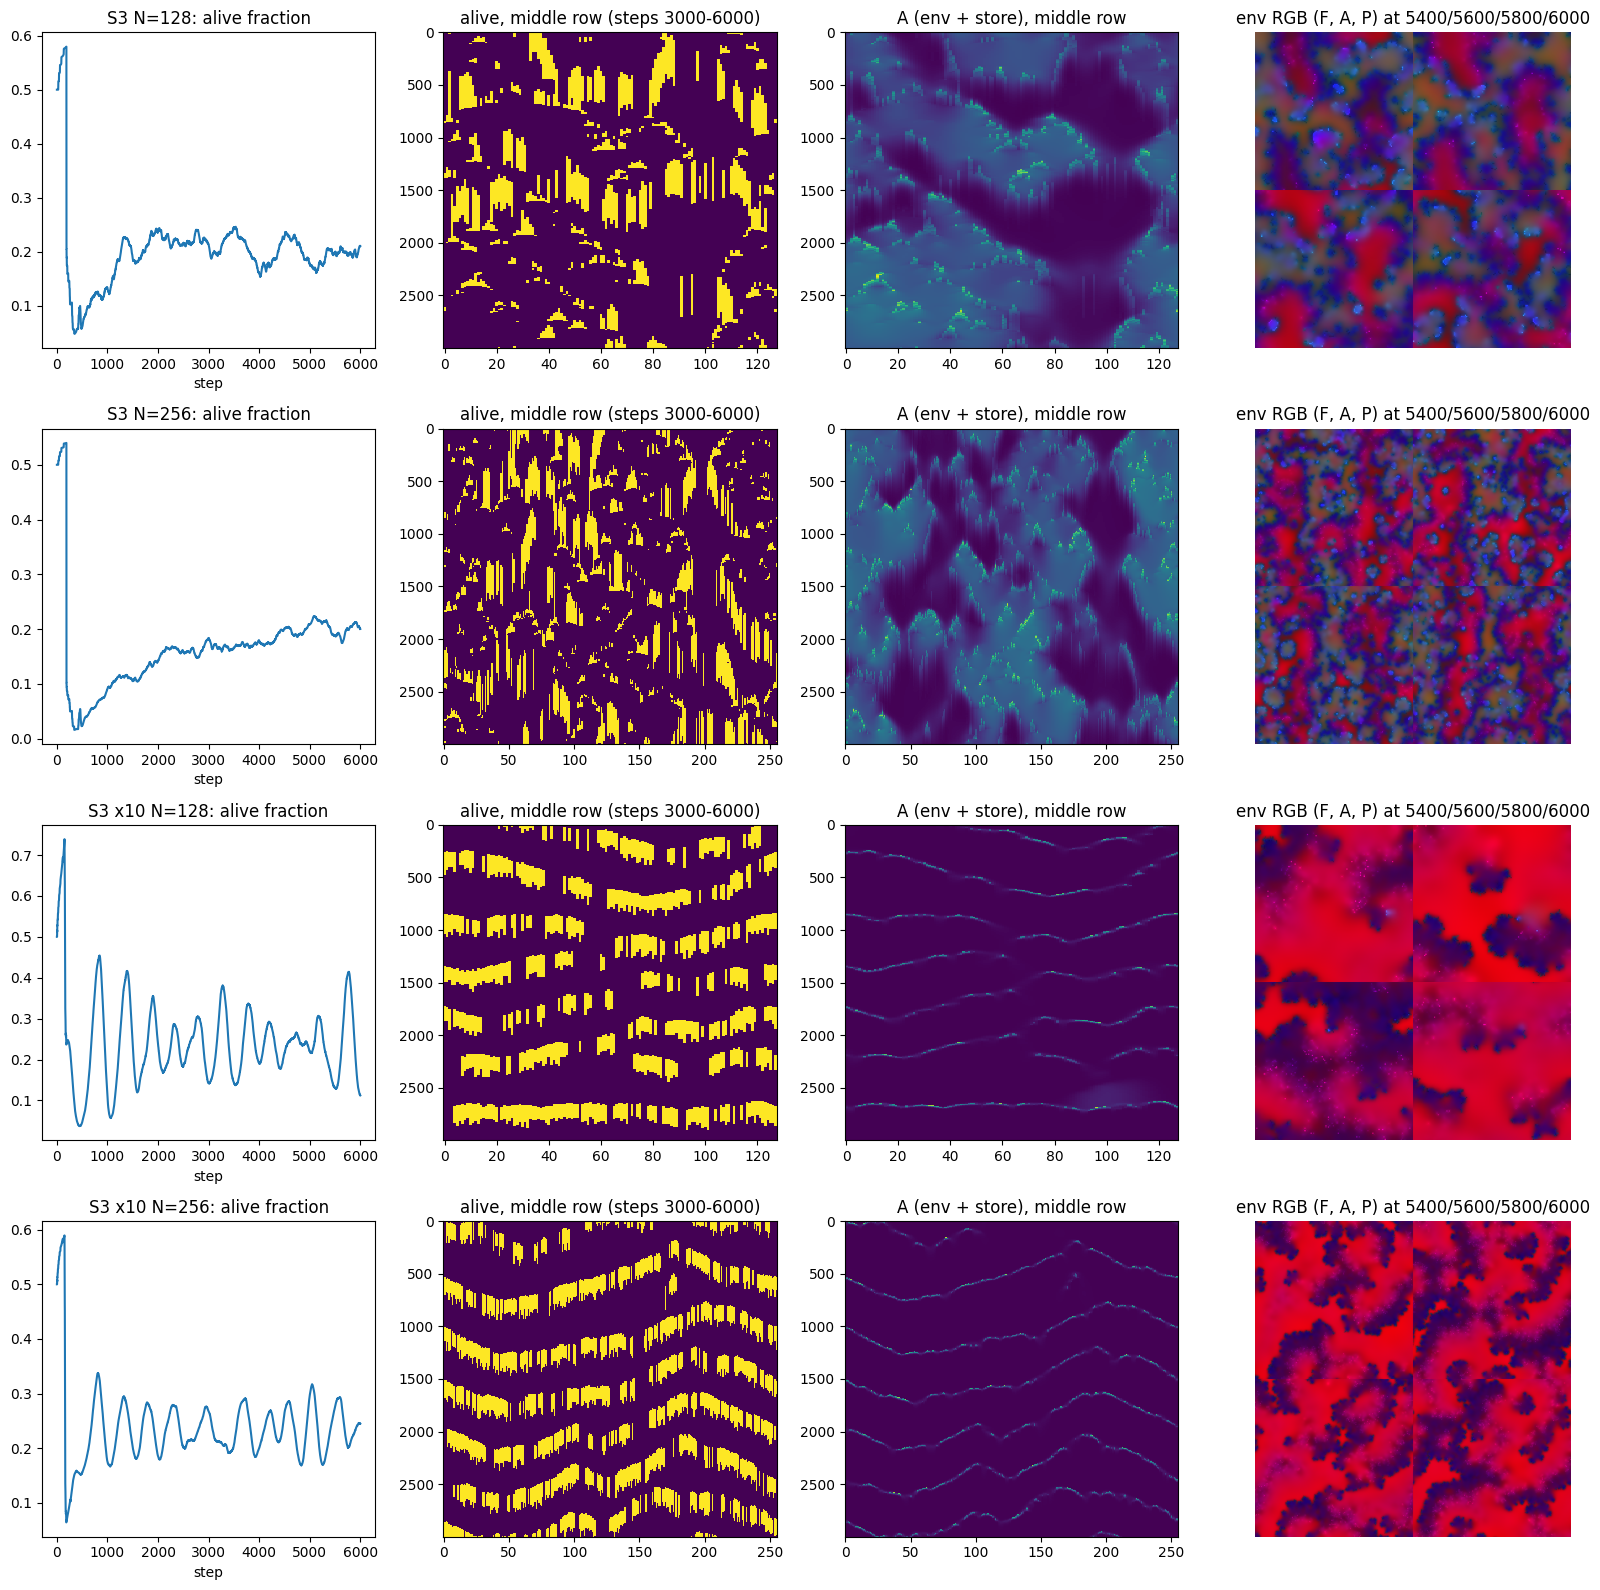

PASS gs3 S3 persists 6000 steps at N=128 and 256 


In [7]:
S3 = {}
CASES = [('S3', 128, {}), ('S3', 256, {}), ('S3 x10', 128, dict(k_min=0.01)), ('S3 x10', 256, dict(k_min=0.01))]
fig, axs = plt.subplots(4, 4, figsize=(16, 16))
for i, (tag, N, kw) in enumerate(CASES):
    s = cp.build_chemca(dict(model='chemca', preset='gs3', **kw), N=N, seed=1)
    alive, kym_a, kym_A, frames = [], [], [], []
    for t in range(1, 6001):
        s.step(); alive.append(s.population() / N ** 2)
        if t > 3000:
            kym_a.append(s.get_alive()[N // 2].astype(float))
            kym_A.append((s.get_E('A') + s.get_store('A'))[N // 2])
        if t in (5400, 5600, 5800, 6000):
            frames.append(s.rgb(0))
    s.free()
    alive = np.array(alive); kym_a = np.array(kym_a); kym_A = np.array(kym_A)
    S3[(tag, N)] = dict(alive_mean=alive[2000:].mean(), alive_std=alive[2000:].std(), alive_min=alive[2000:].min(),
                 site_period_alive=evoca_waves.site_period(kym_a), site_period_A=evoca_waves.site_period(kym_A),
                 global_period=evoca_waves.period_of(alive[2000:], 1))
    print(tag, N, {k: (round(float(v), 3) if not isinstance(v, tuple) else tuple(round(float(x), 2) for x in v))
                   for k, v in S3[(tag, N)].items()})
    axs[i, 0].plot(alive); axs[i, 0].set_title(f'{tag} N={N}: alive fraction'); axs[i, 0].set_xlabel('step')
    axs[i, 1].imshow(kym_a, aspect='auto', interpolation='nearest'); axs[i, 1].set_title('alive, middle row (steps 3000-6000)')
    axs[i, 2].imshow(kym_A, aspect='auto', interpolation='nearest'); axs[i, 2].set_title('A (env + store), middle row')
    axs[i, 3].imshow(np.concatenate([np.concatenate(frames[:2], 1), np.concatenate(frames[2:], 1)], 0))
    axs[i, 3].set_title('env RGB (F, A, P) at 5400/5600/5800/6000'); axs[i, 3].axis('off')
fig.tight_layout(); plt.show()
check('gs3 S3 persists 6000 steps at N=128 and 256', all(S3[('S3', N)]['alive_min'] > 0 for N in (128, 256)))

## 5. Isologous diversification with genes frozen (mu_rgene = mu_ractive = 0)

composition_clusters on the final stores plus their 100-step averages. A positive (k >= 2)
must then be checked against position: the diagnostic below compares each cluster's number
of alive neighbors and its energy. Clusters that separate by neighbor count are colony
interior versus edge (environmental), not cell-intrinsic types.

In [8]:
for pre in ('fw2', 'gs3'):
    for seed in (1, 2):
        r = cp.run_chemca(dict(model='chemca', preset=pre), n_steps=3000, N=128, seed=seed, kymo_steps=600)
        print(f"{pre} seed {seed}: clusters {r['n_comp_clusters']}, silhouette {r['comp_silhouette']:.2f}, "
              f"fractions {np.round(r['comp_fractions'], 2).tolist()}, cells {r['comp_n_cells']}")
    s = cp.build_chemca(dict(model='chemca', preset=pre), N=128, seed=1); s.step(3000)
    rc = cp.composition_clusters(s); al = s.get_alive() == 1
    S = np.stack([s.get_store(c)[al] for c in s.compounds]).T; X = S / S.sum(1, keepdims=True)
    if rc['n_clusters'] > 1:
        lab = np.argmin(((X[:, None, :] - rc['centers'][None]) ** 2).sum(-1), 1)
        A = al.astype(int); nb = sum(np.roll(np.roll(A, i, 0), j, 1) for i in (-1, 0, 1) for j in (-1, 0, 1)) - A
        for j in range(rc['n_clusters']):
            print(f"   {pre} cluster {j}: frac {(lab == j).mean():.2f}, composition {np.round(rc['centers'][j][:len(s.compounds)], 2)}, "
                  f"alive neighbors {nb[al][lab == j].mean():.1f}, e {s.get_e()[al][lab == j].mean():.2f}")
    s.free()

fw2 seed 1: clusters 2, silhouette 0.63, fractions [0.78, 0.22], cells 3916


fw2 seed 2: clusters 2, silhouette 0.64, fractions [0.79, 0.21], cells 3924


   fw2 cluster 0: frac 0.84, composition [0.11 0.89], alive neighbors 6.3, e 0.60
   fw2 cluster 1: frac 0.16, composition [0.27 0.73], alive neighbors 3.7, e 0.69


gs3 seed 1: clusters 2, silhouette 0.51, fractions [0.62, 0.38], cells 1939


gs3 seed 2: clusters 2, silhouette 0.52, fractions [0.59, 0.41], cells 1828


## 6. Summary

In [9]:
for k, v in RESULTS.items():
    print('PASS' if v else 'FAIL', k)
print(f"\n{sum(RESULTS.values())}/{len(RESULTS)} checks pass")
assert all(RESULTS.values())

PASS conversion m=2 matches exponential integrator
PASS fw2: mass identity (rel. err < 1e-6)
PASS fw2: energy identity (abs. err < 1e-9)
PASS fw2: population persists 1500 steps at N=128
PASS gs3: mass identity (rel. err < 1e-6)
PASS gs3: energy identity (abs. err < 1e-9)
PASS gs3: population persists 1500 steps at N=128
PASS recipe round trip: identical state hash
PASS recipe without model loads as EvoCA
PASS build_sim dispatches to ChemCA
PASS make_sim dispatches to ChemCA
PASS mass gate: divides on the first step with body >= 2 x birth mass
PASS composition_clusters: homogeneous -> 1, two planted -> 2
PASS gs3 S3 persists 6000 steps at N=128 and 256

14/14 checks pass
